# Exercise 3: Text Generation using transformers

## Introduction

In this exercise, we will explore the use of Transfromer models for language modeling and text generation. You will implement both character-based and word-based text generation tasks, using the TED2013 dataset.

## Tasks

### Task 1: Prepare the Corpus
1. Load the text corpus `TED2013.ar-en.en` and perform the following preprocessing steps:
   - Convert all text to lowercase.
   - Remove any special characters or punctuation marks.
   
2. Prepare the corpus for both character-based and word-based text generation:
   - For both cases, create sequences of fixed length.
   - Generate input-output pairs for training the models.

### Task 2: Build the Language Models (LM)
1. Create a character-based language model using Keras and TensorFlow, and train it on the preprocessed corpus.
   
2. Similarly, create a word-based language model using Keras and TensorFlow, and train it as well.

3. Generate text from a given seed:
   - First, use the character-based model to generate text.
   - Then, use the word-based model to generate text.








In [1]:

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Rosey\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Rosey\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

Total number of sentences: 145096
Average sentence length: 16.03 words
Max sentence length: 50 words
Min sentence length: 3 words


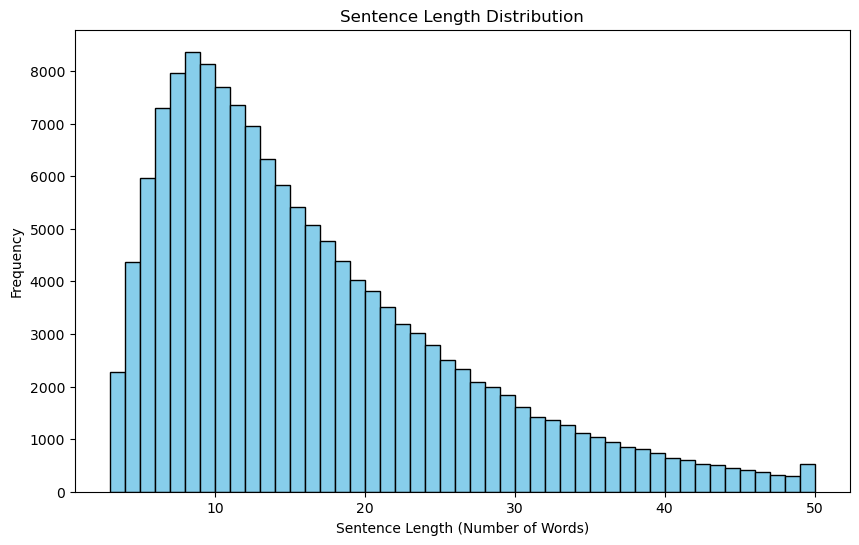

['stephen palumbi following the mercury trail', 'it can be a very complicated thing the ocean', 'and it can be a very complicated thing what human health is', 'and bringing those two together might seem a very daunting task but what im going to try to say is that even in that complexity theres some simple themes that i think if we understand we can really move forward', 'and those simple themes arent really themes about the complex science of whats going on but things that we all pretty well know']


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
import re
import matplotlib.pyplot as plt

import nltk


def load_text_corpus(file_path):
    """
    Load a text corpus from a file, tokenize into sentences using nltk, and perform basic text preprocessing.

    Input:
    - file_path (str): Path to the text file to be loaded.

    Output:
    - tuple: (preprocessed_text, sentences)
      - preprocessed_text (str): A single string of the cleaned and preprocessed text.
      - sentences (list): A list of tokenized sentences.

    """

    # Open and read the content of the file
    with open(file_path, 'r', encoding='utf-8') as file:
        lines = file.readlines()  # Read the file line by line

    sentences_tok = []
    for line in lines:

        # Clean the line: replace non-alphanumeric chars (except spaces) with nothing
        # This keeps "world" from "world." instead of deleting it.
        clean_line = re.sub(r'[^a-zA-Z\s]', '', line.lower())

        # Tokenize cleaned line
        sentence_tokens = nltk.tokenize.sent_tokenize(clean_line)

        # Filter: Allow longer sentences (e.g., up to 50 words) to capture context
        sentence_tokens = [s for s in sentence_tokens if len(s.split()) > 2 and len(s.split()) <= 50]

        sentences_tok.extend(sentence_tokens)


    # Rejoin the sentences
    preprocessed_text = ". ".join(sentences_tok)

    return preprocessed_text, sentences_tok




def plot_sentence_length_stats(sentences):
    """
    Plot sentence length distribution and print sentence statistics.

    Goal: Generate statistics about sentence lengths and visualize the distribution.

    Input:
    - text (str): The text corpus to analyze.

    Output:
    - None: This function prints statistics and displays a bar chart.
    """

    # Compute sentence lengths (in terms of number of words)
    sentence_lengths = [len(sentence.split()) for sentence in sentences]

    # Print sentence length statistics
    print(f"Total number of sentences: {len(sentences)}")
    print(f"Average sentence length: {sum(sentence_lengths) / len(sentence_lengths):.2f} words")
    print(f"Max sentence length: {max(sentence_lengths)} words")
    print(f"Min sentence length: {min(sentence_lengths)} words")

    # Plot the distribution of sentence lengths
    plt.figure(figsize=(10, 6))
    plt.hist(sentence_lengths, bins=range(min(sentence_lengths), max(sentence_lengths) + 1, 1), color='skyblue', edgecolor='black')
    plt.title('Sentence Length Distribution')
    plt.xlabel('Sentence Length (Number of Words)')
    plt.ylabel('Frequency')
    plt.show()

file_path = "TED2013.ar-en.en"
preprocessed_text, sentences_tok = load_text_corpus(file_path)
plot_sentence_length_stats(sentences_tok)
print(sentences_tok[:5])



In [3]:


# Character-level Text Generation
def create_char_level_sequences(text, seq_len=5):
    # 1. Tokenize the whole text first
    tokenizer = Tokenizer(char_level=True)
    tokenizer.fit_on_texts([text])
    vocab_size = len(tokenizer.word_index) + 1

    # Get sequence of integers
    total_sequence = tokenizer.texts_to_sequences([text])[0]

    sequences = []
    targets = []

    # 2. Create windows on integers
    # step=1 creates maximum data. If it crashes RAM, use step=3 or step=5
    step = 3
    for i in range(0, len(total_sequence) - seq_len, step):
        sequences.append(total_sequence[i:i + seq_len])
        targets.append(total_sequence[i + seq_len])

    X = np.array(sequences)
    y = np.array(targets)

    return X, y, vocab_size, tokenizer

toy_text_for_chars = "the dog is shasing the cat"
X_chars_toy, y_chars_toy, vocab_size_toy, tokenizer_chars_toy = create_char_level_sequences(text = toy_text_for_chars, seq_len=10)
print(tokenizer_chars_toy.word_index)
print(X_chars_toy[0])
print(y_chars_toy[0])
print(X_chars_toy[1])
print(y_chars_toy[1])


{' ': 1, 't': 2, 'h': 3, 's': 4, 'e': 5, 'g': 6, 'i': 7, 'a': 8, 'd': 9, 'o': 10, 'n': 11, 'c': 12}
[ 2  3  5  1  9 10  6  1  7  4]
1
[ 1  9 10  6  1  7  4  1  4  3]
8


In [4]:
X_chars, y_chars, vocab_size_chars, tokenizer_chars = create_char_level_sequences(text = preprocessed_text, seq_len=40)
print(X_chars.shape,y_chars.shape, len(tokenizer_chars.index_word))
print(X_chars[0])
print(y_chars[0])

(4212091, 40) (4212091,) 28
[ 8  3  2 20  9  2  7  1 20  4 11 13 16 21  6  1 19  5 11 11  5 15  6  7
 18  1  3  9  2  1 16  2 10 14 13 10 17  1  3 10]
4


In [5]:
# Word-level Text Generation
MAX_VOCAB_SIZE = 10000

def create_word_level_sequences(sents, seq_len=10):
    # Use the inspiration code's approach: limit vocab and handle OOV
    tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<unk>")
    tokenizer.fit_on_texts(sents)

    # Vocab size is either the unique words found OR the limit we set
    vocab_size = min(len(tokenizer.word_index) + 1, MAX_VOCAB_SIZE)

    # Convert to sequences
    token_list = tokenizer.texts_to_sequences(sents)
    flat_tokens = [item for sublist in token_list for item in sublist]

    sequences = []
    targets = []

    # Sliding window
    for i in range(0, len(flat_tokens) - seq_len):
        sequences.append(flat_tokens[i:i + seq_len])
        targets.append(flat_tokens[i + seq_len])

    X = np.array(sequences)
    y = np.array(targets)

    return X, y, vocab_size, tokenizer


toy_text_for_words = ["the dog is shasing the cat", "tha cat is shasing the dog"]
X_words_toy, y_words_toy, vocab_size_toy, tokenizer_words_toy = create_word_level_sequences(toy_text_for_words, seq_len=3)
print(tokenizer_words_toy.word_index)
print(X_words_toy[0])
print(y_words_toy[0])
print(X_words_toy[1])
print(y_words_toy[1])



{'<unk>': 1, 'the': 2, 'dog': 3, 'is': 4, 'shasing': 5, 'cat': 6, 'tha': 7}
[2 3 4]
5
[3 4 5]
2


In [6]:
X_words, y_words, vocab_size_words, tokenizer_words = create_word_level_sequences(sentences_tok, seq_len=10)
print(X_words.shape,y_words.shape, len(tokenizer_words.index_word))
print(X_words[80])
print(y_words[80])

(2326109, 10) (2326109,) 47931
[ 54  21  23  84   7  12  30 289  82  51]
3


In [7]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, Dense, Dropout, LayerNormalization, MultiHeadAttention, Add
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Positional Encoding Function
def positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, np.newaxis]
    i = np.arange(d_model)[np.newaxis, :]
    angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
    angle_rads = pos * angle_rates
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    return tf.cast(angle_rads, dtype=tf.float32)

# Build Transformer-based Model
def build_seq_transformer(seq_len, vocab_size, units=128, num_heads=4, ff_dim=128, dropout=0.1):
    """
    Goal: Build a Transformer model for sequence generation (e.g., predicting the next word).
          This model includes Causal Masking to ensure the model only looks at past tokens.

    Input:
    - seq_len (int): Length of the input sequence.
    - vocab_size (int): Number of unique tokens in the vocabulary.
    - units (int): Dimensionality of the embeddings and hidden layers.
    - num_heads (int): Number of attention heads.
    - ff_dim (int): Dimensionality of the internal Feed-Forward network.
    - dropout (float): Dropout rate.

    Output:
    - model (tf.keras.Model): Compiled Keras model.
    """

    # ==============================================================================
    # 1. INPUTS AND EMBEDDINGS
    # ==============================================================================
    # TODO: Define the input layer.
    # - Instruction: Use 'layers.Input'. Shape should be (seq_len,).
    # - Assign to variable 'inputs'.
    inputs = Input(shape=(seq_len,))

    # TODO: Create Word Embeddings.
    # - Instruction: Use 'layers.Embedding'. Input dim is 'vocab_size', output dim is 'units'.
    # - Instruction: Apply this layer to 'inputs'.
    # - Assign to variable 'embedding'.
    embedding = Embedding(vocab_size, units)(inputs)
    

    # ==============================================================================
    # 2. POSITIONAL ENCODING
    # ==============================================================================
    # TODO: Add Positional Encoding.
    # - Instruction: Call the 'positional_encoding' function (assumed to be defined elsewhere).
    #   Pass 'seq_len' and 'units'.
    # - Instruction: Add (+) the result to the 'embedding' tensor.
    #   (This injects order information into the word vectors).
    embedding = embedding + positional_encoding(seq_len, units)
    

    # ==============================================================================
    # 3. CAUSAL MASKING
    # ==============================================================================
    # We need a mask that looks like a lower-triangular matrix.
    # 1 0 0
    # 1 1 0
    # 1 1 1
    # This ensures position N can only attend to positions 0 through N.

    # TODO: Create the Causal Mask.
    # - Instruction: Create a matrix of ones with shape (seq_len, seq_len) using 'tf.ones'.
    # - Instruction: Use 'tf.linalg.band_part(matrix, -1, 0)'.
    #   (-1 means keep all lower diagonal, 0 means keep 0 upper diagonal).
    # - Assign to variable 'causal_mask'.
    causal_mask = tf.linalg.band_part(tf.ones((seq_len, seq_len)), -1, 0)
    

    # ==============================================================================
    # 4. TRANSFORMER BLOCK (Self-Attention)
    # ==============================================================================
    # This block allows the sequence to look at itself (Self-Attention) to understand context.

    # --- A. Multi-Head Attention ---
    # TODO: Initialize MultiHeadAttention.
    # - Instruction: Use 'layers.MultiHeadAttention'.
    # - Instruction: Set 'num_heads' and 'key_dim' (set key_dim to 'units').
    # - Instruction: call the layer. Important: Set 'query' and 'value' both to 'embedding'.
    # - Instruction: Pass 'attention_mask=causal_mask' to the call.
    # - Assign result to 'attention_output'.

    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=units)(
        query=embedding, value=embedding, attention_mask=causal_mask
    )
    
    
    # --- B. Add & Norm (Residual Connection 1) ---
    # TODO: Apply Dropout and Add Residual connection.
    # - Instruction: Apply 'layers.Dropout' to 'attention_output'.
    # - Instruction: Use 'layers.Add()' to add the original 'embedding' and the new 'attention_output'.
    #   (This is the Skip Connection).
    # - Instruction: Apply 'layers.LayerNormalization(epsilon=1e-6)' to the result.
    # - Update the variable 'attention_output'.
    attention_output = Dropout(dropout)(attention_output)
    attention_output = Add()([embedding, attention_output])
    attention_output = LayerNormalization(epsilon=1e-6)(attention_output)

    # ==============================================================================
    # 5. FEED-FORWARD NETWORK
    # ==============================================================================
    # The FFN processes the information gathered by the attention mechanism.

    # --- A. Dense Layers ---
    # TODO: Create the Feed-Forward layers.
    # - Instruction: Create a 'layers.Dense' with 'ff_dim' units and 'relu' activation. Apply to 'attention_output'.
    # - Instruction: Create a second 'layers.Dense' with 'units' (project back to original size). Apply to the previous result.
    # - Assign final result to 'ff_output'.

    ff_output = Dense(ff_dim, activation='relu')(attention_output)
    ff_output = Dense(units)(ff_output)
    # --- B. Add & Norm (Residual Connection 2) ---
    # TODO: Apply Dropout and Add Residual connection.
    # - Instruction: Apply 'layers.Dropout' to 'ff_output'.
    # - Instruction: Use 'layers.Add()' to add the 'attention_output' (from before the FFN) and the new 'ff_output'.
    # - Instruction: Apply 'layers.LayerNormalization(epsilon=1e-6)'.
    # - Update the variable 'ff_output'.
    ff_output = Dropout(dropout)(ff_output)
    ff_output = Add()([attention_output, ff_output])
    ff_output = LayerNormalization(epsilon=1e-6)(ff_output)

    # ==============================================================================
    # 6. OUTPUT LAYER (Next Token Prediction)
    # ==============================================================================
    # We want to predict the next word in the vocabulary.
    # For a generation task, we often only care about the output of the very last time step.

    # TODO: Create the Output Dense Layer.
    # - Instruction: Slice 'ff_output' to get only the last token: 'ff_output[:, -1, :]'.
    # - Instruction: Create a 'layers.Dense' layer with 'vocab_size' units and 'softmax' activation.
    # - Apply this layer to the sliced tensor.
    # - Assign to variable 'outputs'.
    outputs = Dense(vocab_size, activation='softmax')(ff_output[:, -1, :])
    

    # ==============================================================================
    # 7. COMPILATION
    # ==============================================================================
    # TODO: Instantiate and Compile.
    # - Instruction: Create 'models.Model(inputs=inputs, outputs=outputs)'.
    model = Model(inputs=inputs, outputs=outputs)
    
    # - Instruction: Create the optimizer. Use 'optimizers.Adam'.
    # - Instruction: Set 'learning_rate=0.001'.
    # - Instruction: Set 'clipnorm=1.0'.
    #   (Gradient clipping prevents the "exploding gradient" problem common in Transformers).
    optimizer = Adam(learning_rate=0.001, clipnorm=1.0)

    # - Instruction: Compile the model.
    # - Loss: 'sparse_categorical_crossentropy' (since targets are integers, not one-hot).
    # - Metrics: ['accuracy'].
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    return model

# Model architecture
def print_model_architecture(model, input_shape):
    """Print the model architecture (layers, names, and shapes)."""
    model.build(input_shape)
    print("Model Architecture:")
    print("=" * 40)
    model.summary()
    print("=" * 40 + "\n\n")


seq_len_chars = len(X_chars[0])
vocab_size_chars = len(tokenizer_chars.index_word)+1
# Character-Level Transformer Language Model
print("Language Model:")
char_model = build_seq_transformer(seq_len=seq_len_chars, vocab_size=vocab_size_chars)
print_model_architecture(char_model, input_shape=(None, seq_len_chars))


seq_len_words = len(X_words[0])
vocab_size_words = len(tokenizer_words.index_word)+1
# Character-Level Transformer Language Model
print("Language Model:")
word_model = build_seq_transformer(seq_len=seq_len_words, vocab_size=vocab_size_words)
print_model_architecture(word_model, input_shape=(None, seq_len_words))


Language Model:
Model Architecture:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 40, 128)   │      3,712 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 40, 128)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 40, 128)   │    263,808 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 40, 128)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 40, 128)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 40, 128)   │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 40, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 40, 128)   │     16,512 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 40, 128)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 40, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 40, 128)   │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 128)       │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 29)        │      3,741 │ get_item[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 304,797 (1.16 MB)

 Trainable params: 304,797 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 10, 128)   │  6,135,296 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 10, 128)   │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 128)   │    263,808 │ add_3[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 10, 128)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 10, 128)   │          0 │ add_3[0][0],      │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 128)   │        256 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 10, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 10, 128)   │     16,512 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 10, 128)   │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 10, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 128)   │        256 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 128)       │          0 │ layer_normalizat… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 47932)     │  6,183,228 │ get_item_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,615,868 (48.13 MB)

 Trainable params: 12,615,868 (48.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Train character-level model
char_model.fit(X_chars, y_chars, epochs=15, batch_size=256)


In [ ]:

# Train character-level model
word_model.fit(X_words, y_words, epochs=15, batch_size=256)


In [ ]:

# Generate text from model predictions
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def generate_text(model, tokenizer, seed_text, seq_len, max_gen_len=100, model_is_char_based=True, temperature=0.7):
    """
    Goal: Generate new text using the trained Transformer/RNN model.
          This function handles the iterative process of:
          1. Preprocessing the current window of text.
          2. Predicting the next token probability distribution.
          3. Applying 'Temperature' to adjust randomness.
          4. Sampling the next token and updating the window.

    Input:
    - model: The trained Keras model.
    - tokenizer: The Keras tokenizer object.
    - seed_text (str): The starting text to prompt the generation.
    - seq_len (int): The sequence length the model was trained on.
    - max_gen_len (int): How many tokens to generate.
    - model_is_char_based (bool): True if character-level generation, False if word-level.
    - temperature (float): Controls diversity.
      (Lower = more deterministic/repetitive, Higher = more random/creative).

    Output:
    - (str): The fully generated text.
    """

    # ==============================================================================
    # 1. SETUP INPUT LISTS
    # ==============================================================================
    # We need a mutable list to keep track of the growing text.

    # TODO: Convert the seed_text to a list.
    # - Instruction: Check 'if model_is_char_based:'.
    # - True Case: Convert 'seed_text' to a list of characters (e.g., list("hello") -> ['h','e',...]).
    # - False Case: Split 'seed_text' by spaces (e.g., "hello world".split()).
    # - Assign the result to a variable named 'input_text'.
    if model_is_char_based:
        input_text = list(seed_text)
    else:
        input_text = seed_text.split()
    
    # TODO: Initialize the output tracker.
    # - Instruction: Create a copy of 'input_text' and assign it to 'generated_output'.
    #   (We will return this list joined together at the very end).

    generated_output = input_text.copy()
    # TODO: Get the Out-Of-Vocabulary (OOV) index.
    # - Instruction: Look up the index for the token '<unk>' in 'tokenizer.word_index'.
    # - Assign to 'oov_index'. (Use .get() to avoid errors if it doesn't exist).
    oov_index = tokenizer.word_index.get('<unk>', 1)

    print(f"Generating with temperature: {temperature}...")


    # ==============================================================================
    # 2. GENERATION LOOP
    # ==============================================================================
    # TODO: Loop 'max_gen_len' times.
    for _ in range(max_gen_len):

        # --- A. Prepare the Sequence ---
        # We must take the last 'seq_len' items from our growing list and turn them
        # back into a string so the tokenizer can process them.
        
        

        # TODO: Select the current window.
        # - Instruction: Slice 'input_text' to get the last 'seq_len' elements.
        # - Instruction: If 'model_is_char_based', join them with empty string "".
        # - Instruction: Else, join them with a space " ".
        # - Assign to variable 'current_window'.
        current_window = input_text[-seq_len:]
        if model_is_char_based:
            current_window = "".join(current_window)
        else:
            current_window = " ".join(current_window)
        # TODO: Tokenize and Pad.
        # - Instruction: Convert 'current_window' to a sequence using 'tokenizer.texts_to_sequences'.
        #   (Note: Pass it as a list: [current_window]).
        # - Instruction: Pad this sequence using 'pad_sequences'.
        #   (maxlen=seq_len, padding='pre').
        # - Assign to variable 'seq'.
        seq = tokenizer.texts_to_sequences([current_window])
        seq = pad_sequences(seq, maxlen=seq_len, padding='pre')
        

        # --- B. Model Prediction ---
        # TODO: Get raw predictions.
        # - Instruction: Call 'model.predict(seq)'. Set verbose=0.
        # - Assign to 'preds'.
        preds = model.predict(seq, verbose=0)
        
        # TODO: Extract the probability distribution for the *next* token.
        # - Instruction: Check the shape of 'preds'.
        # - Case 1 (2D shape): If shape is (batch, vocab), take 'preds[0, :]'.
        # - Case 2 (3D shape): If shape is (batch, seq, vocab), the model returns predictions for every step.
        #   We only care about the last step. Take 'preds[0, -1, :]'.
        # - Assign the result to 'predictions'.
        if len(preds.shape) == 2:
            predictions = preds[0, :]
        else:
            predictions = preds[0, -1, :]
        

        # --- C. Masking (Optional but Recommended) ---
        # TODO: Suppress unwanted tokens.
        # - Instruction: Set the probability of index 0 (padding) to 0.0.
        # - Instruction: If 'oov_index' exists, set that index to 0.0 as well.
        predictions[0] = 0.0
        if oov_index:
            predictions[oov_index] = 0.0
        

        # --- D. Temperature Sampling ---
        # To control randomness, we modify the probabilities using the Temperature formula:
        # P_i = exp(log(y_i) / T) / Sum(...)

        # TODO: Apply Temperature.
        # - Instruction: Convert 'predictions' to 'float64' (for precision).
        # - Instruction: Compute the logarithm: np.log(predictions + 1e-10).
        #   (Add a tiny epsilon 1e-10 to prevent log(0) error).
        # - Instruction: Divide this log result by 'temperature'.
        # - Instruction: Apply exponentiation: np.exp(...).
        # - Instruction: Normalize by dividing the array by its sum.
        # - Update 'predictions' with this new probability distribution.
        predictions = predictions.astype('float64')
        predictions = np.log(predictions + 1e-10) / temperature
        predictions = np.exp(predictions)
        predictions = predictions / np.sum(predictions)
        
        # TODO: Sample from the distribution.
        # - Instruction: Use 'np.random.multinomial(1, predictions, 1)'.
        # - Instruction: Use 'np.argmax' to find the index of the selected token.
        # - Assign to 'next_token_idx'.
        next_token_idx = np.argmax(np.random.multinomial(1, predictions, 1))
        
        # TODO: Safety Catch.
        # - Instruction: If 'next_token_idx' is 0 (padding was somehow selected),
        #   fallback to the most likely token (argmax of the raw predictions) + 1.
        if next_token_idx == 0:
            next_token_idx = np.argmax(preds[0]) + 1
        

        # --- E. Decode and Update ---
        # TODO: Convert Index to Word/Char.
        # - Instruction: Look up 'next_token_idx' in 'tokenizer.index_word'.
        # - Assign to 'next_token'.
        next_token = tokenizer.index_word.get(next_token_idx, '')
        
    
        # TODO: Update the lists.
        # - Instruction: Append 'next_token' to 'input_text'.
        # - Instruction: Append 'next_token' to 'generated_output'.
        input_text.append(next_token)
        generated_output.append(next_token)

    # ==============================================================================
    # 3. FINAL RETURN
    # ==============================================================================
    # TODO: Return the full string.
    # - Instruction: If 'model_is_char_based', join 'generated_output' with "".
    # - Instruction: Else, join 'generated_output' with " ".
    if model_is_char_based:
        return "".join(generated_output)
    else:
        return " ".join(generated_output)


seq_len_chars = len(X_chars[0])
seed_text = "i said hello"
generated_text_char = generate_text(char_model, tokenizer_chars, seed_text, seq_len_chars, model_is_char_based=True)
print("Generated text (char level):", generated_text_char)

seq_len_words = len(X_words[0])
seed_text = "he have been staying at home with his"
generated_text_word = generate_text(word_model, tokenizer_words, seed_text, seq_len_words, model_is_char_based=False)
print("Generated text (word level):", generated_text_word)


In [ ]:
import math

def calculate_perplexity(model, X_test, y_test):
    print(f"Evaluating model on {len(X_test)} samples...")

    # 1. Get the standard Cross Entropy Loss from Keras
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    # 2. Perplexity = exp(loss)
    perplexity = math.exp(loss)

    return perplexity


# Calculate perplexity
char_perplexity = calculate_perplexity(char_model, X_chars[:1000], y_chars[:1000])
word_perplexity = calculate_perplexity(word_model, X_words[:1000], y_words[:1000])

print(f"Character-Level Perplexity: {char_perplexity}")
print(f"Word-Level Perplexity: {word_perplexity}")
